# Validation against the reference runs

Compares `gyaradax` runs with the reference runs of [gerkone/gyaradax-tests](https://huggingface.co/datasets/gerkone/gyaradax-tests):

- the test cases (`nonlinear/`, `linear/`, `kinetic/`), whose JSON diagnostics cover the whole GKW run,
- the long-horizon references (`long_horizon/`), with a nonlinear and a linear run per case.

The notebook does not run simulations. It reads the output directories of `gyaradax run` (`fluxes.npz`, `kyspec.npz`, `kxspec.npz`, `growth.npz`) and compares them with the JSON diagnostics, so make the runs first, one output directory per case under `RUNS`. Only the JSON diagnostics and the configs of the dataset are needed, about 40 MB:

```bash
ROOT=~/.cache/gyaradax/test_data RUNS=runs
hf download gerkone/gyaradax-tests --repo-type dataset --local-dir $ROOT --include "*.json" "*.yaml" "*input*.dat" "*.md"
# from the repository root: every case has a config in configs/{adiabatic,kinetic}/{nonlinear,linear}
gyaradax run configs/adiabatic/nonlinear/itg_weak_drive.yaml --output-dir $RUNS/nonlinear/itg_weak_drive
gyaradax run configs/kinetic/nonlinear/itg_mid_flux.yaml --output-dir $RUNS/long_horizon/kinetic_itg_mid_flux/nonlinear
gyaradax run configs/kinetic/linear/itg_mid_flux.yaml --output-dir $RUNS/long_horizon/kinetic_itg_mid_flux/linear
```

The next cell lists the cases and prints the command for each missing run. Cases without a run are skipped, and runs that have not reached the reference averaging window are left out of the statistics. Turbulent runs separate from the reference within tens of $R/v_{th}$, so the comparison is statistical: time-averaged fluxes and spectra over the reference window, and the converged linear growth rates.

In [1]:
import os
import sys

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from gyaradax.diagnostics.plot_utils import plot_run_fluxes, plot_run_spectra

sys.path.append("..")
from validation_stats import (
    aggregate_results,
    compare_config,
    compare_linear,
    load_reference,
    load_run,
    reference_cases,
    reference_configs,
    results_to_markdown,
    run_window,
)

ROOT = os.path.expanduser(os.environ.get("GYARADAX_TEST_DATA") or "~/.cache/gyaradax/test_data")
RUNS = os.environ.get("GYARADAX_VALIDATION_RUNS", os.path.join("..", "runs"))
if not os.path.exists(os.path.join(ROOT, "manifest.json")):
    from huggingface_hub import snapshot_download

    snapshot_download(
        repo_id="gerkone/gyaradax-tests",
        repo_type="dataset",
        local_dir=ROOT,
        allow_patterns=["*.json", "*.yaml", "*input*.dat", "*.md"],
    )

In [2]:
def run_dirs(label):
    kind = label.split("/")[0]
    base = os.path.join(RUNS, label)
    if kind == "long_horizon":
        return os.path.join(base, "nonlinear"), os.path.join(base, "linear")
    return (None, base) if kind == "linear" else (base, None)


def has(d, f):
    return d if d and os.path.exists(os.path.join(d, f)) else None


cases = []
for label, case_dir in reference_cases(ROOT):
    nl_dir, lin_dir = run_dirs(label)
    cases.append(
        {
            "label": label,
            "nl_ref": load_reference(case_dir, "nonlinear"),
            "lin_ref": load_reference(case_dir, "linear"),
            "nl_dir": has(nl_dir, "fluxes.npz"),
            "lin_dir": has(lin_dir, "growth.npz"),
        }
    )
for c in cases:
    nl = "-" if c["nl_ref"] is None else ("run" if c["nl_dir"] else "no run")
    if c["nl_dir"] and load_run(c["nl_dir"])["time"][-1] < c["nl_ref"]["average"]["window"][0]:
        nl = "partial"
    lin = "-" if c["lin_ref"] is None else ("run" if c["lin_dir"] else "no run")
    print(f"{c['label']:42s} nonlinear: {nl:7s} linear: {lin}")


CONFIGS = reference_configs("..")


def run_command(c, kind):
    """Command that makes the missing run, from the repository root, with $RUNS as in the first cell."""
    out = os.path.join("$RUNS", c["label"], kind) if c["label"].startswith("long_horizon/") else f"$RUNS/{c['label']}"
    return f"gyaradax run {CONFIGS[c['label'] + '/' + kind + '.json']} --output-dir {out}"


missing = [
    run_command(c, kind)
    for c in cases
    for kind, ref, run in (("nonlinear", c["nl_ref"], c["nl_dir"]), ("linear", c["lin_ref"], c["lin_dir"]))
    if ref is not None and run is None
]
if missing:
    print(f"\n{len(missing)} runs missing:")
    print("\n".join(missing))

nonlinear/itg_steep_density                nonlinear: no run  linear: -
nonlinear/itg_high_shear                   nonlinear: no run  linear: -
nonlinear/itg_flat_density                 nonlinear: no run  linear: -
nonlinear/itg_weak_drive                   nonlinear: run     linear: -
nonlinear/itg_low_shear_strong_drive       nonlinear: no run  linear: -
linear/itg_weak_high_shear                 nonlinear: -       linear: no run
linear/itg_strong_low_shear                nonlinear: -       linear: run
linear/itg_flat_density                    nonlinear: -       linear: no run
kinetic/kinetic_low_te_gradient            nonlinear: no run  linear: -
kinetic/kinetic_mid_te_gradient            nonlinear: no run  linear: -
kinetic/kinetic_high_te_gradient           nonlinear: no run  linear: -
long_horizon/adiabatic_itg_high_shear      nonlinear: run     linear: run
long_horizon/adiabatic_itg_high_q          nonlinear: run     linear: run
long_horizon/kinetic_tem_low_flux          nonli

## 1. Fluxes

Heat flux of each species, reference in black. The shaded band is the reference averaging window.

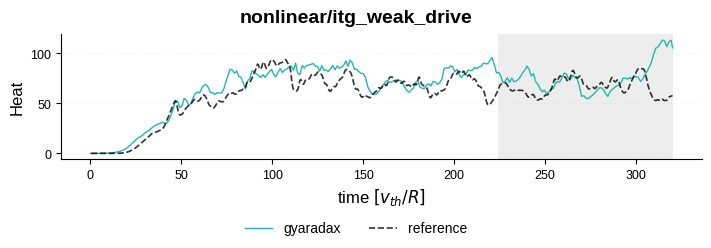

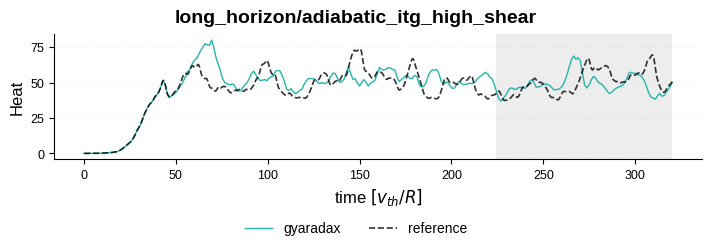

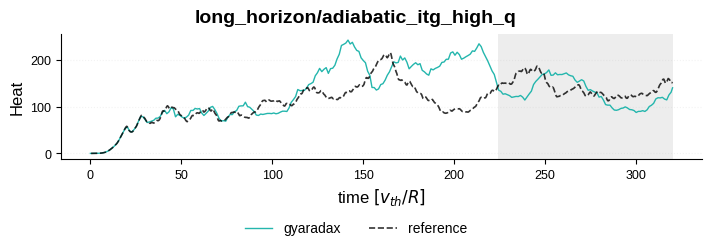

In [3]:
nl_cases = [c for c in cases if c["nl_ref"] and c["nl_dir"]]
for c in nl_cases:
    plot_run_fluxes({"gyaradax": c["nl_dir"]}, c["nl_ref"], channels=("heat",), title=c["label"])
    plt.show()

## 2. Spectra

$k_y$ and $k_x$ spectra of $|\phi|^2$, averaged over the reference window (or the same fraction at the end of a shorter run). The bands are the standard deviation over the window.

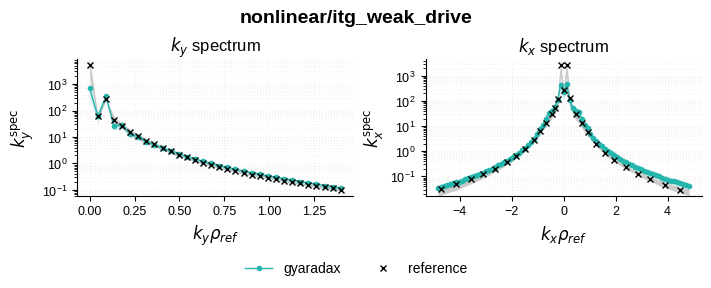

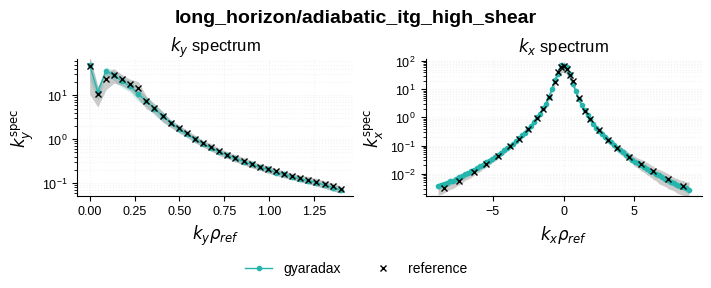

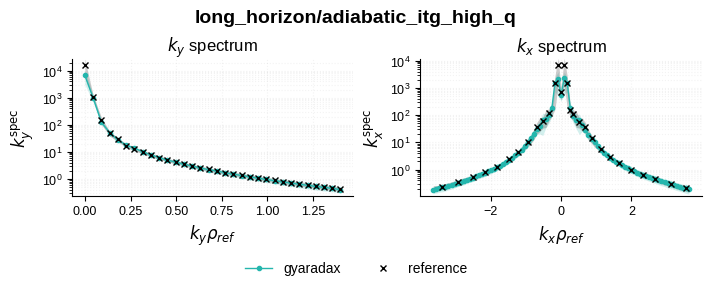

In [4]:
for c in nl_cases:
    run = load_run(c["nl_dir"])
    if "ky_spec" in run:
        plot_run_spectra({"gyaradax": run}, c["nl_ref"], window=run_window(run["time"], c["nl_ref"]), title=c["label"])
        plt.show()

## 3. Linear growth rates

Growth rate at the end of each linear run against the converged reference. The relative difference is reported over the $k_y$ with $\gamma$ above a quarter of the maximum.

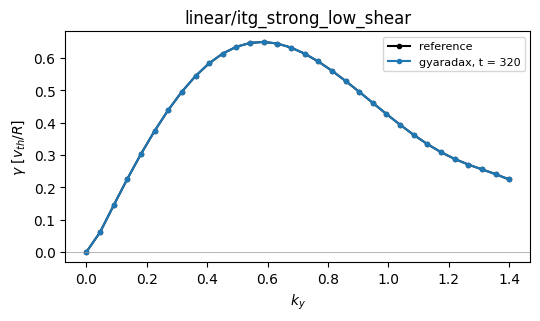

linear/itg_strong_low_shear: max relative difference over the unstable ky 6.33e-06


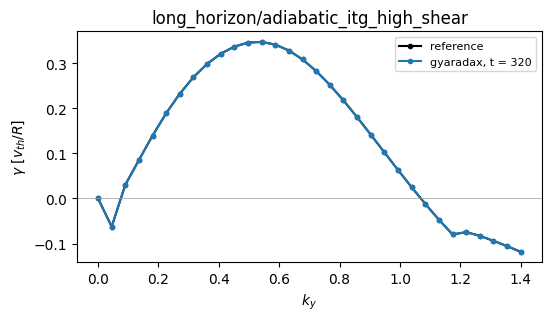

long_horizon/adiabatic_itg_high_shear: max relative difference over the unstable ky 1.13e-04


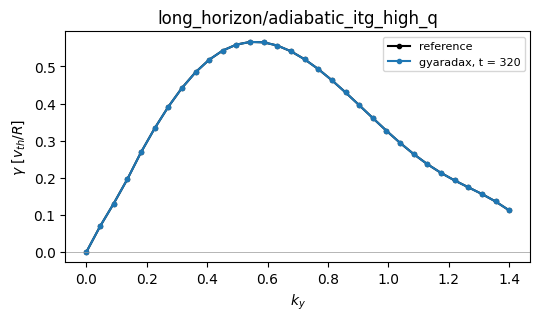

long_horizon/adiabatic_itg_high_q: max relative difference over the unstable ky 1.85e-05


In [5]:
for c in [c for c in cases if c["lin_ref"] and c["lin_dir"]]:
    res = compare_linear(c["lin_dir"], c["lin_ref"])
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.plot(res["ky"], res["ref_gamma"], "k.-", label="reference")
    ax.plot(res["ky"], res["sim_gamma"], ".-", label=f"gyaradax, t = {res['t_end']:.0f}")
    ax.axhline(0, color="0.6", lw=0.5)
    ax.set(xlabel=r"$k_y$", ylabel=r"$\gamma$ [$v_{th}/R$]", title=c["label"])
    ax.legend(fontsize=8)
    plt.show()
    print(f"{c['label']}: max relative difference over the unstable ky {res['max_rel_diff']:.2e}")

## 4. Statistical validation

Quantitative comparison of the ion channel of every nonlinear run with a reference:

- **Spectra**: KS test, Pearson correlation, relative $L_2$ error on the time-averaged $k_x$ and $k_y$ spectra
- **Growth rates**: mean $\pm$ std of the time-averaged growth rate profile
- **Flux averages**: mean $\pm$ autocorrelation-corrected standard error, and the $z$ score of the difference

In [6]:
all_stats = {c["label"]: compare_config([c["nl_dir"]], c["nl_ref"], species=0) for c in nl_cases}
all_stats = {k: v for k, v in all_stats.items() if v is not None}
aggregated = aggregate_results(all_stats)
if aggregated:
    display(Markdown(results_to_markdown(aggregated, per_config=all_stats)))
else:
    print(f"no nonlinear runs under {RUNS}")

**Statistical validation: gyaradax vs reference** (aggregated over 3 trajectories)

**Stationarity (ADF+KPSS):** 0/3 trajectories stationary

| | KS stat | Pearson r (p) | Log rel. L2 |
|---|---|---|---|
| ky spectrum | 0.164 +/- 0.125 | 0.965 +/- 0.035 (< 0.001) | 0.088 +/- 0.047 |
| kx spectrum | 0.089 +/- 0.049 | 0.950 +/- 0.031 (< 0.001) | 0.089 +/- 0.052 |

| | gamma_sim +/- std | gamma_ref +/- std |
|---|---|---|
| Growth rate | 0.0029 +/- 0.0011 (0.1404 +/- 0.0142) | 0.0016 +/- 0.0025 (0.1844 +/- 0.0162) |

| | sim mean +/- SE | ref mean +/- SE | SE(diff) | rel. diff |
|---|---|---|---|---|
| Gamma_p | -- | -- | -- | -- |
| Q | 84.1721 +/- 33.0477 (+/-10.5105 +/- 7.2613) | 85.8024 +/- 39.2239 (+/-7.0415 +/- 4.3207) | 12.8300 +/- 8.1756 | 0.0857 +/- 0.0417 |
| Pi | -0.0422 +/- 0.1266 (+/-0.8071 +/- 0.3835) | 0.5013 +/- 0.6300 (+/-0.7894 +/- 0.5626) | 1.1464 +/- 0.6511 | 0.7995 +/- 0.2315 |

### Interpretation

- **KS test**: Low statistic ($\lesssim 0.1$) indicates consistent spectral shapes. Note: discrete k-grids limit the test's resolution.
- **Pearson $r$**: Values close to 1.0 confirm spectral shape agreement.
- **Relative $L_2$**: Amplitude-weighted distance in log space; values $\lesssim 0.2$ indicate good quantitative match.
- **Growth rate**: Mean $\pm$ std over the window. Agreement is assessed by overlap of error bars.
- **Flux $z$ score**: $|\mu_\mathrm{sim} - \mu_\mathrm{ref}|$ over the combined standard error; values below 2 are consistent.